In [17]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")
IN_DIR = BASE / "intermediate/stage5_labelled"            # Stage 5 output (1 Hz, labelled)
OUT_DIR = BASE / "intermediate/stage6_segmented"          # Stage 5 data + segment id per second
REPORT_DIR = BASE / "outputs/stage6_segmentation"         # segment table, comparison, figures
INVENTORY = BASE / "outputs/stage1_inventory/inventory.csv"   # only used to report results per route
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

trip_ids = sorted(p.stem for p in IN_DIR.glob("T*.csv"))
route = (pd.read_csv(INVENTORY).set_index("trip_id")["route_hint"] if INVENTORY.exists() else pd.Series(dtype=str))
print(f"{len(trip_ids)} labelled trips from Stage 5 | routes known for {route.reindex(trip_ids).notna().sum()} trips")

77 labelled trips from Stage 5 | routes known for 77 trips


In [18]:
CFG = {
    # --- what counts as a stop
    "stop_kmh": 2.0,             # below 2 km/h the EV is standing (absorbs interpolation wobble around 0)
    "min_stop_s": 3,             # a stop lasts >= 3 s (about one OBD polling cycle of 3.7 s); shorter dips = creeping
    # --- what counts as a real micro-trip (otherwise merged into the next one)
    "min_drive_s": 10,           # at least 10 s of movement ...
    "min_drive_peak_kmh": 10,    # ... reaching at least 10 km/h
    # --- long stop-free stretches (expressway cruising)
    "max_segment_s": 900,        # stop-free driving longer than 15 min is cut into equal parts
    "cut_search_s": 120,         # each cut is placed at the steadiest second within +/- 2 min of the ideal point
    "steady_window_s": 5,        # steadiness = mean |acceleration| over 5 s
    # --- quality flags
    "min_segment_s": 20,         # shorter pieces (e.g. squeezed between environment changes) are excluded
    "max_interp_share": 0.9,     # speed > 90 % interpolated -> too little measured data
    "long_idle_s": 300,          # a stop > 5 min at the start of a micro-trip is flagged (possible parking)
    # --- settings of the comparison methods (section 5 only)
    "fixed_window_s": 120,       # fixed-duration windows
    "cp_min_size_s": 30,         # change-point: shortest segment
    "cp_min_shift_kmh": 10,      # change-point: a split must explain a ~10 km/h shift in mean speed over 30 s
    "accel_event_ms2": 0.5,      # |a| above this at a cut = the cut splits an acceleration / braking event
}
pd.Series(CFG, name="value").to_frame()

,value
stop_kmh,2.0
min_stop_s,3.0
min_drive_s,10.0
min_drive_peak_kmh,10.0
max_segment_s,900.0
cut_search_s,120.0
steady_window_s,5.0
min_segment_s,20.0
max_interp_share,0.9
long_idle_s,300.0


## 1. Candidate methods

The methodology asks for several methods to be evaluated before one is chosen. They are compared on the same data
in section 5.

In [19]:
methods = pd.DataFrame([
    ("Fixed-duration windows", f"cut every {CFG['fixed_window_s']} s",
     "simple, equal sizes", "cuts through stops, accelerations and environment changes; ends rarely at rest"),
    ("Stop-to-stop micro-trips", "cut at every real stop",
     "standard in driving-cycle research; both ends at rest", "ignores environment changes; one long expressway run = one huge segment"),
    ("Change-point detection", "cut where the mean speed level shifts (binary segmentation)",
     "follows changes in driving regime", "cuts during acceleration; depends on a penalty; ends rarely at rest"),
    ("Environment-aware adaptive (selected)", "blocks per environment, stop-to-stop inside, long cruises cut at steady points",
     "one environment per segment, ends at rest where possible, cruising kept long", "more rules to explain"),
], columns=["method", "how it cuts", "strength", "weakness"])
methods.to_csv(REPORT_DIR / "candidate_methods.csv", index=False)
methods

,method,how it cuts,strength,weakness
0,Fixed-duration windows,cut every 120 s,"simple, equal sizes","cuts through stops, accelerations and environm..."
1,Stop-to-stop micro-trips,cut at every real stop,standard in driving-cycle research; both ends ...,ignores environment changes; one long expressw...
2,Change-point detection,cut where the mean speed level shifts (binary ...,follows changes in driving regime,cuts during acceleration; depends on a penalty...
3,Environment-aware adaptive (selected),"blocks per environment, stop-to-stop inside, l...","one environment per segment, ends at rest wher...",more rules to explain


## 2. Segmentation functions

In [20]:
def runs_of(mask):
    """(start, end_exclusive) index pairs of consecutive True values."""
    m = np.r_[False, np.asarray(mask, bool), False].astype(int)
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))


def load_trip(tid):
    d = pd.read_csv(IN_DIR / f"{tid}.csv")
    d["timestamp"] = pd.to_datetime(d["timestamp"], format="ISO8601")
    d["environment"] = d["environment"].fillna("Unknown").astype(str)
    return d


def acceleration(d):
    """Acceleration (m/s2) per second, never across a logging gap (NaN at the first second of each segment)."""
    return (d.groupby("segment_id")["speed_kmh"].diff() / 3.6).values


def edge_reason(d, i):
    """Why a block starts at row i (or the previous block ends at row i - 1)."""
    if i <= 0 or i >= len(d):
        return "trip_edge"
    if d["segment_id"].iat[i] != d["segment_id"].iat[i - 1]:
        return "logging_gap"
    if pd.isna(d["speed_kmh"].iat[i]) or pd.isna(d["speed_kmh"].iat[i - 1]):
        return "missing_speed"
    if d["environment"].iat[i] != d["environment"].iat[i - 1]:
        return "env_change"
    return "other"


def blocks(d, by_environment=True):
    """Rows with speed, split at logging gaps and (optionally) environment changes."""
    has_speed = d["speed_kmh"].notna().values
    key = d["segment_id"].astype(str).values
    if by_environment:
        key = key + "|" + d["environment"].values
    out = []
    for a, b in runs_of(has_speed):
        start = a
        for i in range(a + 1, b + 1):
            if i == b or key[i] != key[start]:
                out.append((start, i))
                start = i
    return out


def stop_starts(v, a, b):
    """Row indices in [a, b) where a real stop begins (speed < stop_kmh for >= min_stop_s)."""
    still = v[a:b] < CFG["stop_kmh"]
    return [a + s for s, e in runs_of(still) if e - s >= CFG["min_stop_s"]]


def is_real_drive(v):
    moving = v >= CFG["stop_kmh"]
    return moving.sum() >= CFG["min_drive_s"] and np.nanmax(v) >= CFG["min_drive_peak_kmh"]


def micro_trips(v, a, b, start_reason, end_reason):
    """Stop-to-stop pieces of block [a, b); creeping pieces merged into the next one. Returns [a, b, why_start, why_end]."""
    cuts = [s for s in stop_starts(v, a, b) if s > a]
    edges = [a] + cuts + [b]
    pieces = [[edges[k], edges[k + 1], "stop" if k > 0 else start_reason, "stop" if k < len(cuts) else end_reason]
              for k in range(len(edges) - 1)]
    k = 0
    while k < len(pieces) and len(pieces) > 1:          # merge creeping / idle-only pieces
        p = pieces[k]
        if is_real_drive(v[p[0]:p[1]]):
            k += 1
            continue
        if k < len(pieces) - 1:                          # into the next micro-trip
            nxt = pieces.pop(k + 1)
            p[1], p[3] = nxt[1], nxt[3]
        else:                                            # last piece (e.g. final idle) -> into the previous one
            prev = pieces[k - 1]
            prev[1], prev[3] = p[1], p[3]
            pieces.pop(k)
            k -= 1
    return pieces


def cut_long(piece, abs_acc_smooth):
    """Cut a piece longer than max_segment_s into equal parts at the steadiest second near each ideal cut."""
    a, b, why_a, why_b = piece
    n = int(np.ceil((b - a) / CFG["max_segment_s"]))
    if n <= 1:
        return [piece]
    cuts = []
    for k in range(1, n):
        ideal = a + round(k * (b - a) / n)
        lo = max(a + CFG["min_segment_s"], ideal - CFG["cut_search_s"], (cuts[-1] if cuts else a) + CFG["min_segment_s"])
        hi = min(b - CFG["min_segment_s"], ideal + CFG["cut_search_s"])
        window = abs_acc_smooth[lo:hi + 1]
        if len(window) == 0 or np.all(np.isnan(window)):
            cuts.append(ideal)
            continue
        best = np.nanmin(window)                         # steadiest value; among ties take the one nearest the ideal
        cand = lo + np.where(window <= best + 0.02)[0]
        cuts.append(int(cand[np.argmin(np.abs(cand - ideal))]))
    edges = [a] + cuts + [b]
    return [[edges[k], edges[k + 1], why_a if k == 0 else "length_cut", why_b if k == n - 1 else "length_cut"]
            for k in range(n)]


def segment_adaptive(d):
    """The selected method. Returns a list of [a, b, why_start, why_end] row ranges."""
    v = d["speed_kmh"].values
    acc = np.abs(acceleration(d))
    acc_smooth = pd.Series(acc).rolling(CFG["steady_window_s"], center=True, min_periods=1).mean().values
    out = []
    for a, b in blocks(d, by_environment=True):
        for p in micro_trips(v, a, b, edge_reason(d, a), edge_reason(d, b)):
            out += cut_long(p, acc_smooth)
    return out

In [21]:
def describe(d, tid, k, piece):
    """Metadata and quality flag of one segment."""
    a, b, why_a, why_b = piece
    s = d.iloc[a:b]
    v = s["speed_kmh"].values
    moving = v >= CFG["stop_kmh"]
    env = s["environment"].iat[0]
    conf = s["env_confidence"].astype(str)
    start_at_rest = why_a == "stop" or v[0] < CFG["stop_kmh"]
    end_at_rest = why_b == "stop" or v[-1] < CFG["stop_kmh"]
    r = {"seg_uid": f"{tid}_S{k:03d}", "trip_id": tid, "route": route.get(tid, "unknown"),
         "logging_segment": int(s["segment_id"].iat[0]), "environment": env,
         "start_t_s": int(s["t_s"].iat[0]), "end_t_s": int(s["t_s"].iat[-1]),
         "start_time": s["timestamp"].iat[0], "duration_s": b - a,
         "distance_km": round(float(v.sum()) / 3600, 3),
         "mean_speed_kmh": round(float(v.mean()), 1), "max_speed_kmh": round(float(v.max()), 1),
         "moving_s": int(moving.sum()),
         "lead_idle_s": int(np.argmax(moving)) if moving.any() else b - a,
         "start_reason": why_a, "end_reason": why_b,
         "start_at_rest": bool(start_at_rest), "end_at_rest": bool(end_at_rest),
         "interpolated_share": round(float((s["speed_flag"] == "interpolated").mean()), 3),
         "env_high_conf_share": round(float((conf == "high").mean()), 3),
         "env_low_conf_share": round(float((conf == "low").mean()), 3)}

    exclude = []
    if env == "Unknown":
        exclude.append("no environment label")
    if r["duration_s"] < CFG["min_segment_s"]:
        exclude.append(f"shorter than {CFG['min_segment_s']} s")
    if r["moving_s"] == 0:
        exclude.append("no movement")
    if r["interpolated_share"] > CFG["max_interp_share"]:
        exclude.append("speed mostly interpolated")
    # planned cuts: at a stop, or at a steady point inside a long cruise (joinable to another cruise piece)
    start_ok = start_at_rest or why_a == "length_cut"
    end_ok = end_at_rest or why_b == "length_cut"
    partial = []
    if not start_ok:
        partial.append(f"starts while moving ({why_a})")
    if not end_ok:
        partial.append(f"ends while moving ({why_b})")
    if r["lead_idle_s"] > CFG["long_idle_s"]:
        partial.append(f"idle > {CFG['long_idle_s']} s at start")
    r["quality"] = "exclude" if exclude else ("partial" if partial else "good")
    r["quality_reason"] = "; ".join(exclude + partial) or "-"
    return r

## 3. Segment all trips

`good` = a complete micro-trip (starts and ends at rest). `partial` = valid driving that starts or ends while moving
(cut by an environment change, a long-cruise cut, a data gap or the trip edge); it is kept for features and clustering
but needs care when segments are joined in Stage 10. `exclude` = not usable (no label, too short, no movement, too
little measured speed).

In [22]:
seg_rows = []
for i, tid in enumerate(trip_ids, 1):
    d = load_trip(tid)
    pieces = segment_adaptive(d)
    d["seg_uid"], d["seg_quality"] = None, None
    for k, p in enumerate(pieces, 1):
        r = describe(d, tid, k, p)
        seg_rows.append(r)
        d.iloc[p[0]:p[1], d.columns.get_loc("seg_uid")] = r["seg_uid"]
        d.iloc[p[0]:p[1], d.columns.get_loc("seg_quality")] = r["quality"]
    d.to_csv(OUT_DIR / f"{tid}.csv", index=False)
    if i % 10 == 0 or i == len(trip_ids):
        print(f"{i}/{len(trip_ids)} trips segmented")

segments = pd.DataFrame(seg_rows)
segments.to_csv(REPORT_DIR / "segments.csv", index=False)
print(f"{len(segments):,} segments saved")
segments.head(100)

10/77 trips segmented
20/77 trips segmented
30/77 trips segmented
40/77 trips segmented
50/77 trips segmented
60/77 trips segmented
70/77 trips segmented
77/77 trips segmented
1,073 segments saved


,seg_uid,trip_id,route,logging_segment,environment,start_t_s,end_t_s,start_time,duration_s,distance_km,mean_speed_kmh,max_speed_kmh,moving_s,lead_idle_s,start_reason,end_reason,start_at_rest,end_at_rest,interpolated_share,env_high_conf_share,env_low_conf_share,quality,quality_reason
0,T001_S001,T001,Route B,0,Urban,1,92,2026-08-03 07:01:33,92,0.763,29.9,36.2,84,8,missing_speed,env_change,True,False,0.728,0.000,0.000,partial,ends while moving (env_change)
1,T001_S002,T001,Route B,0,Expressway,93,125,2026-08-03 07:03:05,33,0.273,29.8,34.5,33,0,env_change,stop,False,True,0.727,0.576,0.000,partial,starts while moving (env_change)
2,T001_S003,T001,Route B,0,Expressway,126,601,2026-08-03 07:03:38,476,10.376,78.5,89.8,464,12,stop,missing_speed,True,False,0.729,0.695,0.099,partial,ends while moving (missing_speed)
3,T001_S004,T001,Route B,0,Expressway,686,1162,2026-08-03 07:12:58,477,11.256,85.0,91.0,477,0,missing_speed,length_cut,False,False,0.736,0.906,0.000,partial,starts while moving (missing_speed)
4,T001_S005,T001,Route B,0,Expressway,1163,1648,2026-08-03 07:20:55,486,10.326,76.5,88.6,486,0,length_cut,stop,False,True,0.737,0.802,0.056,good,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,T009_S026,T009,Route A,0,Urban,2634,2675,2026-08-10 08:43:18,42,0.149,12.7,27.9,34,8,stop,stop,True,True,0.738,0.000,0.000,good,-
96,T009_S027,T009,Route A,0,Urban,2676,2716,2026-08-10 08:44:00,41,0.274,24.1,50.7,30,11,stop,stop,True,True,0.732,0.000,0.000,good,-
97,T009_S028,T009,Route A,0,Urban,2717,2735,2026-08-10 08:44:41,19,0.052,9.8,20.3,13,6,stop,stop,True,True,0.737,0.000,0.000,exclude,shorter than 20 s
98,T009_S029,T009,Route A,0,Urban,2736,2849,2026-08-10 08:45:00,114,0.457,14.4,30.2,111,3,stop,stop,True,True,0.728,0.000,0.000,good,-


In [23]:
order = ["Urban", "Suburban", "Intercity", "Rural", "Expressway", "Unknown"]
by_env = segments.groupby("environment").agg(
    segments=("seg_uid", "count"),
    good=("quality", lambda q: int((q == "good").sum())),
    partial=("quality", lambda q: int((q == "partial").sum())),
    exclude=("quality", lambda q: int((q == "exclude").sum())),
    hours=("duration_s", lambda s: s.sum() / 3600),
    km=("distance_km", "sum"),
    median_duration_s=("duration_s", "median"),
    median_distance_km=("distance_km", "median"),
    median_mean_speed_kmh=("mean_speed_kmh", "median"),
)
usable = segments[segments["quality"] != "exclude"]
by_env["usable_hours"] = usable.groupby("environment")["duration_s"].sum() / 3600
by_env = by_env.reindex([e for e in order if e in by_env.index]).fillna(0).round(2)
for e in ["Urban", "Suburban", "Intercity", "Rural", "Expressway"]:
    if e not in by_env.index:
        print(f"No {e} driving in this dataset -> no {e} segments (a coverage limitation, not an error)")
by_env.to_csv(REPORT_DIR / "segments_by_environment.csv")
by_env

No Intercity driving in this dataset -> no Intercity segments (a coverage limitation, not an error)
No Rural driving in this dataset -> no Rural segments (a coverage limitation, not an error)


,segments,good,partial,exclude,hours,km,median_duration_s,median_distance_km,median_mean_speed_kmh,usable_hours
environment,,,,,,,,,,
Urban,757,561,173,23,25.57,555.43,89.0,0.50,19.3,25.47
Suburban,133,7,120,6,2.04,45.78,46.0,0.30,25.0,2.01
Expressway,161,42,118,1,16.31,1248.72,315.0,6.22,68.8,16.31
Unknown,22,0,0,22,1.03,42.51,119.5,1.00,27.4,0.00


In [24]:
reasons = (segments.assign(reason=segments["quality_reason"].str.split("; ")).explode("reason")
           .query("reason != '-'").groupby(["quality", "reason"]).size().rename("segments").reset_index()
           .sort_values(["quality", "segments"], ascending=[True, False]))
reasons.to_csv(REPORT_DIR / "quality_reasons.csv", index=False)
print("Why segments are 'partial' or 'exclude' (a segment can have several reasons):")
reasons

Why segments are 'partial' or 'exclude' (a segment can have several reasons):


,quality,reason,segments
3,exclude,shorter than 20 s,30
4,exclude,starts while moving (env_change),25
2,exclude,no environment label,22
0,exclude,ends while moving (env_change),14
5,exclude,starts while moving (missing_speed),4
1,exclude,ends while moving (missing_speed),2
6,partial,ends while moving (env_change),203
8,partial,starts while moving (env_change),192
9,partial,starts while moving (missing_speed),31
7,partial,ends while moving (missing_speed),27


In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Figures

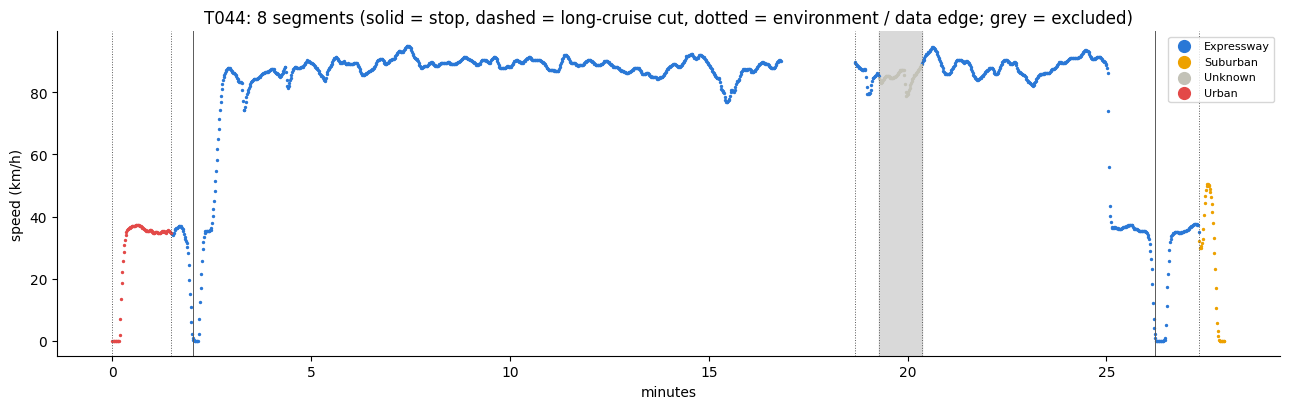

In [26]:
colors = {"Urban": "#e34948", "Suburban": "#eda100", "Intercity": "#1baf7a", "Rural": "#6250d6",
          "Expressway": "#2a78d6", "Unknown": "#c3c2b7"}
# example: the trip with the most environments, then the most segments
pick = segments.groupby("trip_id").agg(envs=("environment", "nunique"), n=("seg_uid", "count"))
example = pick.sort_values(["envs", "n"], ascending=False).index[0]
d = pd.read_csv(OUT_DIR / f"{example}.csv")
segs = segments[segments["trip_id"] == example]

fig, ax = plt.subplots(figsize=(13, 4.2))
for env, g in d.groupby("environment"):
    ax.scatter(d.loc[g.index, "t_s"] / 60, d.loc[g.index, "speed_kmh"], s=2, color=colors.get(env, "#52514e"), label=env)
for _, s in segs.iterrows():
    ls = "-" if s["start_reason"] == "stop" else ("--" if s["start_reason"] == "length_cut" else ":")
    ax.axvline(s["start_t_s"] / 60, color="0.35", lw=0.7, ls=ls)
    if s["quality"] == "exclude":
        ax.axvspan(s["start_t_s"] / 60, (s["end_t_s"] + 1) / 60, color="0.85", zorder=0)
ax.set(xlabel="minutes", ylabel="speed (km/h)",
       title=f"{example}: {len(segs)} segments (solid = stop, dashed = long-cruise cut, dotted = environment / data edge; grey = excluded)")
ax.legend(markerscale=6, fontsize=8, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "segmentation_example.png", dpi=150)
plt.show()

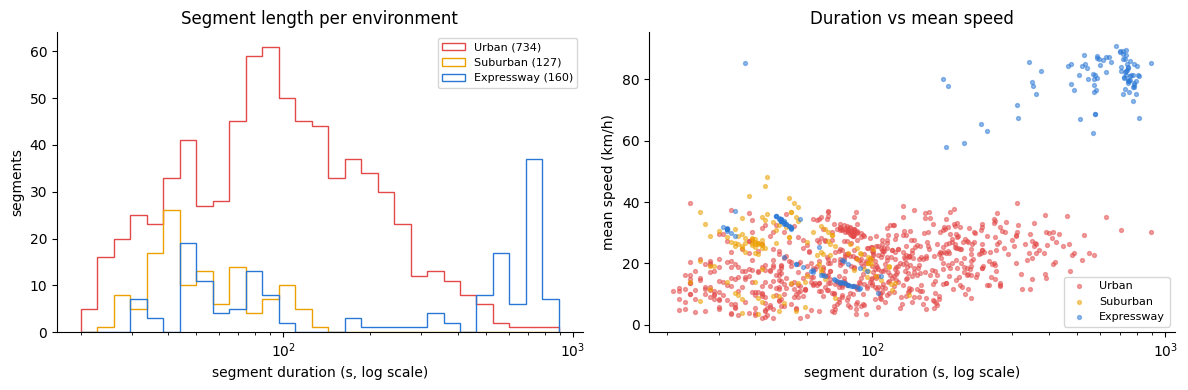

In [27]:
use = segments[segments["quality"] != "exclude"]
envs = [e for e in order if e in set(use["environment"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(np.log10(CFG["min_segment_s"]), np.log10(max(use["duration_s"].max(), 100)), 30)
for e in envs:
    x = use.loc[use["environment"] == e]
    axes[0].hist(x["duration_s"], bins=bins, histtype="step", lw=2, color=colors[e], label=f"{e} ({len(x)})")
    axes[1].scatter(x["duration_s"], x["mean_speed_kmh"], s=8, alpha=0.5, color=colors[e], label=e)
axes[0].set(xscale="log", xlabel="segment duration (s, log scale)", ylabel="segments", title="Segment length per environment")
axes[1].set(xscale="log", xlabel="segment duration (s, log scale)", ylabel="mean speed (km/h)", title="Duration vs mean speed")
for ax in axes:
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "segment_distributions.png", dpi=150)
plt.show()

## 5. Method comparison

All four candidates are run on the same trips and scored on what matters for building driving cycles:

| Metric | Why it matters | Better |
|---|---|---|
| `mixed_env_%` | a segment must belong to one environment, or its cycle is contaminated | low |
| `cuts_at_rest_%` | cuts at standstill keep whole micro-trips and let segments be joined without speed jumps | high |
| `cuts_in_accel_%` | a cut during acceleration / braking destroys a driving event | low |
| `expressway_segs_per_h` | many tiny expressway pieces = unnecessary fragmentation of cruising | low (but not 1 per trip) |
| `short_%` | segments under 20 s carry little information | low |

In [28]:
def segment_fixed(d):
    w, out = CFG["fixed_window_s"], []
    for a, b in blocks(d, by_environment=False):
        out += [[s, min(s + w, b)] for s in range(a, b, w)]
    return out


def segment_stop_to_stop(d):
    v, out = d["speed_kmh"].values, []
    for a, b in blocks(d, by_environment=False):
        out += [p[:2] for p in micro_trips(v, a, b, "edge", "edge")]
    return out


def binary_segmentation(v, min_size, penalty):
    """Piecewise-constant mean speed (least squares). Split while the gain exceeds the penalty."""
    cs, cs2 = np.r_[0, np.cumsum(v)], np.r_[0, np.cumsum(v * v)]
    sse = lambda a, b: (cs2[b] - cs2[a]) - (cs[b] - cs[a]) ** 2 / (b - a)
    out, stack = [], [(0, len(v))]
    while stack:
        a, b = stack.pop()
        if b - a < 2 * min_size:
            out.append((a, b)); continue
        k = np.arange(a + min_size, b - min_size + 1)
        cost = ((cs2[k] - cs2[a]) - (cs[k] - cs[a]) ** 2 / (k - a)) + ((cs2[b] - cs2[k]) - (cs[b] - cs[k]) ** 2 / (b - k))
        j = int(np.argmin(cost))
        if sse(a, b) - cost[j] > penalty:
            stack += [(a, int(k[j])), (int(k[j]), b)]
        else:
            out.append((a, b))
    return sorted(out)


def segment_changepoint(d):
    v, out = d["speed_kmh"].values, []
    pen = CFG["cp_min_size_s"] * CFG["cp_min_shift_kmh"] ** 2
    for a, b in blocks(d, by_environment=False):
        out += [[a + s, a + e] for s, e in binary_segmentation(v[a:b].astype(float), CFG["cp_min_size_s"], pen)]
    return out


def score(d, pieces):
    """Per-trip counts for the comparison metrics."""
    v, env = d["speed_kmh"].values, d["environment"].values
    acc = np.abs(acceleration(d))
    ends = {p[1] for p in pieces}
    internal = [p[0] for p in pieces                     # cuts between two touching pieces of the same logging segment
                if p[0] in ends and d["segment_id"].iat[p[0]] == d["segment_id"].iat[p[0] - 1]]
    at_rest = [min(v[i - 1], v[i]) < CFG["stop_kmh"] for i in internal]
    # a cut splits an event only if the car is MOVING at the cut and accelerating / braking there
    # (arriving at a stop ends the braking; that is not a split)
    in_acc = [(not rest) and bool(np.max(np.nan_to_num(acc[max(i - 1, 0):i + 2])) > CFG["accel_event_ms2"])
              for i, rest in zip(internal, at_rest)]
    dur = np.array([p[1] - p[0] for p in pieces])
    main_env = [pd.Series(env[p[0]:p[1]]).mode().iat[0] for p in pieces]
    return {"segments": len(pieces), "durations": dur,
            "mixed": sum(len(set(env[p[0]:p[1]])) > 1 for p in pieces),
            "cuts": len(internal), "at_rest": sum(at_rest), "in_acc": sum(in_acc),
            "exp_segs": sum(e == "Expressway" for e in main_env),
            "exp_hours": float((env[~np.isnan(v)] == "Expressway").sum()) / 3600,
            "short": int((dur < CFG["min_segment_s"]).sum())}


candidates = {"fixed windows": segment_fixed, "stop-to-stop": segment_stop_to_stop,
              "change-point": segment_changepoint, "adaptive (selected)": segment_adaptive}
acc_rows = {m: [] for m in candidates}
for tid in trip_ids:
    d = load_trip(tid)
    for m, f in candidates.items():
        acc_rows[m].append(score(d, f(d)))

rows = []
for m, lst in acc_rows.items():
    dur = np.concatenate([x["durations"] for x in lst])
    tot = lambda k: sum(x[k] for x in lst)
    rows.append({"method": m, "segments": tot("segments"),
                 "median_s": int(np.median(dur)), "p10_s": int(np.percentile(dur, 10)), "p90_s": int(np.percentile(dur, 90)),
                 "mixed_env_%": round(100 * tot("mixed") / tot("segments"), 1),
                 "cuts_at_rest_%": round(100 * tot("at_rest") / max(tot("cuts"), 1), 1),
                 "cuts_in_accel_%": round(100 * tot("in_acc") / max(tot("cuts"), 1), 1),
                 "expressway_segs_per_h": round(tot("exp_segs") / max(tot("exp_hours"), 1e-9), 1),
                 "short_%": round(100 * tot("short") / tot("segments"), 1)})
comparison = pd.DataFrame(rows).set_index("method")
comparison.to_csv(REPORT_DIR / "method_comparison.csv")
comparison

,segments,median_s,p10_s,p90_s,mixed_env_%,cuts_at_rest_%,cuts_in_accel_%,expressway_segs_per_h,short_%
method,,,,,,,,,
fixed windows,1401,120,120,120,14.8,9.7,19.1,31.2,1.2
stop-to-stop,848,108,36,361,21.2,100.0,0.0,5.9,1.8
change-point,1405,65,30,223,13.5,1.2,78.2,20.2,0.1
adaptive (selected),1073,86,33,361,0.0,74.5,6.1,9.9,2.8


## 6. Verification

In [29]:
checks = {}
seg_by_uid = segments.set_index("seg_uid")
for tid in trip_ids:
    d = pd.read_csv(OUT_DIR / f"{tid}.csv")
    s5 = pd.read_csv(IN_DIR / f"{tid}.csv", usecols=["t_s", "speed_kmh"])
    has_speed = d["speed_kmh"].notna()
    checks.setdefault("same rows and times as Stage 5", []).append(
        len(d) == len(s5) and bool((d["t_s"].values == s5["t_s"].values).all()))
    checks.setdefault("every second with speed is in exactly one segment", []).append(
        bool(d.loc[has_speed, "seg_uid"].notna().all()))
    checks.setdefault("no segment on seconds without speed", []).append(bool(d.loc[~has_speed, "seg_uid"].isna().all()))
    g = d[d["seg_uid"].notna()].groupby("seg_uid", sort=False)
    checks.setdefault("one environment per segment", []).append(bool((g["environment"].nunique() == 1).all()))
    checks.setdefault("no segment crosses a logging gap", []).append(bool((g["segment_id"].nunique() == 1).all()))
    checks.setdefault("chronological, 1 s steps inside segments", []).append(
        bool(g["t_s"].apply(lambda t: (np.diff(t.values) == 1).all()).all()))
    checks.setdefault("segments are contiguous (no id reappears later)", []).append(
        bool((d["seg_uid"].dropna() != d["seg_uid"].dropna().shift()).sum() == d["seg_uid"].nunique()))
    checks.setdefault(f"no segment longer than {CFG['max_segment_s']} s", []).append(
        bool((g.size() <= CFG["max_segment_s"]).all()))
    dist_trip = d["speed_kmh"].sum() / 3600
    dist_segs = seg_by_uid.loc[seg_by_uid["trip_id"] == tid, "distance_km"].sum()
    checks.setdefault("distance preserved (segments = trip, within 0.1 %)", []).append(
        bool(abs(dist_segs - dist_trip) <= 0.001 * max(dist_trip, 1e-6) + 0.005))
stop_starts_ok = segments.loc[segments["start_reason"] == "stop"]
first_speed = []
for tid, g in stop_starts_ok.groupby("trip_id"):
    d = pd.read_csv(OUT_DIR / f"{tid}.csv", usecols=["t_s", "speed_kmh"]).set_index("t_s")["speed_kmh"]
    first_speed += list(d.reindex(g["start_t_s"]).values)
checks["segments that start at a stop start below stop_kmh"] = [bool(np.all(np.array(first_speed) < CFG["stop_kmh"]))]
good = segments[segments["quality"] == "good"]
ok_edge = lambda why, rest: rest | (why == "length_cut")
checks["'good' segments start/end at rest or at a steady-cruise cut"] = [
    bool((ok_edge(good["start_reason"], good["start_at_rest"]) & ok_edge(good["end_reason"], good["end_at_rest"])).all())]

verification = pd.DataFrame({k: [f"{sum(v)}/{len(v)}", "PASS" if all(v) else "CHECK"] for k, v in checks.items()},
                            index=["passing", "result"]).T
verification

,passing,result
same rows and times as Stage 5,77/77,PASS
every second with speed is in exactly one segment,77/77,PASS
no segment on seconds without speed,77/77,PASS
one environment per segment,77/77,PASS
no segment crosses a logging gap,77/77,PASS
"chronological, 1 s steps inside segments",77/77,PASS
segments are contiguous (no id reappears later),77/77,PASS
no segment longer than 900 s,77/77,PASS
"distance preserved (segments = trip, within 0.1 %)",77/77,PASS
segments that start at a stop start below stop_kmh,1/1,PASS


In [30]:
print("STAGE 6 – ADAPTIVE SEGMENTATION: KEY RESULTS")
print("-" * 60)
print("Method: environment-aware stop-to-stop micro-trips "
      f"(stop < {CFG['stop_kmh']} km/h for >= {CFG['min_stop_s']} s; cruises > {CFG['max_segment_s'] // 60} min cut at steady points)")
print(f"Trips: {len(trip_ids)}  |  segments: {len(segments):,}  "
      f"(good {(segments['quality'] == 'good').sum():,}, partial {(segments['quality'] == 'partial').sum():,}, "
      f"exclude {(segments['quality'] == 'exclude').sum():,})")
for env, r in by_env.iterrows():
    print(f"  {env:10s}: {int(r['segments']):5d} segments, {r['usable_hours']:5.1f} usable h, "
          f"median {r['median_duration_s']:.0f} s / {r['median_distance_km']:.2f} km")
a = comparison.loc["adaptive (selected)"]
print(f"Adaptive method: {a['mixed_env_%']}% mixed-environment segments, {a['cuts_at_rest_%']}% of cuts at rest, "
      f"{a['cuts_in_accel_%']}% of cuts during acceleration/braking")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 6 – ADAPTIVE SEGMENTATION: KEY RESULTS
------------------------------------------------------------
Method: environment-aware stop-to-stop micro-trips (stop < 2.0 km/h for >= 3 s; cruises > 15 min cut at steady points)
Trips: 77  |  segments: 1,073  (good 610, partial 411, exclude 52)
  Urban     :   757 segments,  25.5 usable h, median 89 s / 0.50 km
  Suburban  :   133 segments,   2.0 usable h, median 46 s / 0.30 km
  Expressway:   161 segments,  16.3 usable h, median 315 s / 6.22 km
  Unknown   :    22 segments,   0.0 usable h, median 120 s / 1.00 km
Adaptive method: 0.0% mixed-environment segments, 74.5% of cuts at rest, 6.1% of cuts during acceleration/braking
Verification: all checks PASS
